# <a href="https://thetahat.ru/courses/ad">Введение в анализ данных</a>
## Домашнее задание 10. Статистика


**Правила, <font color="red">прочитайте внимательно</font>:**

1. Общее

     * Выполненную работу **в формате `ipynb`** нужно отправить по ссылке "Сдача ДЗ" на <a href="https://thetahat.ru/courses/ad"><b>странице курса</b></a>. **Работы, присланные иным способом, не принимаются.** Дедлайны указаны в боте и на сайте, они являются строгими.
     
     * Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><b>руководство по оформлению ДЗ</b></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.
     
     * Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><b>правила использования ИИ-инструментов</b></a> при решении домашнего задания.
     
     * Выполнять задание необходимо полностью самостоятельно. **При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф -3 скор-балла к итоговой оценке.**
     
     * Решение теоретических задач оформляйте в markdown-ячейках формате $\LaTeX$. При решении можно использовать ИИ-инструменты только для оформления написанного самостоятельно решения. Например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.
     
     * Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/"><img src="https://miptstats.github.io/theta_grader_small.png" style="display: inline; vertical-align: middle;"></a> **ThetaGrader**. Результат проверки валидируется и исправляется человеком, после чего комментарии отправляются студентам.
     </br>

2. Правила заполнения ноутбука

     * Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.
     * Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены `<...>`.
     * Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках.
     * Условия <font color="red"><b>запрещается модифицировать</b></font>.
     * При нарушении данных правил работа может получить 0 баллов.
</br>


**Баллы за задание**

* Задача 1 &mdash; 30 баллов
* Задача 2 &mdash; 30 баллов
* Задача 2 &mdash; 50 баллов

In [ ]:
# Bot check

# HW_ID: fpmi_ad10
# Бот проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так бот проверит, что ты отправляешь финальную версию, а не промежуточную.
# Никакие значения в этой ячейке не влияют на факт сдачи работы.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import time
import torch.nn as nn
import torchvision
from collections import defaultdict
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit

**Примечание об исправлениях**

2 задача:
- В пункте 1 для всех трёх графиков установлен общий масштаб оси X, чтобы можно было визуально сравнивать разброс оценок при разных размерах выборки.
- В пункте 1 добавлена подпись оси X: «Значение оценки дисперсии».
- В пункте 2 исправлен расчёт несмещённой оценки: значения `n` теперь начинаются с 2, поэтому не возникает деления на ноль при вычислении поправки $\frac{n}{n-1}$.
- В пункте 3 добавлено пояснение, почему в лабораторных работах по физике при оценке дисперсии используют знаменатель $n-1$.

3 задача:
- добавлен вывод численных значений доверительных интервалов, длины интервалов.
- изменён итоговый вывод о стратификации под новые значения.

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 1**
1. ссылка
    - для чего использована
    - для чего использована
2. ссылка
    - для чего использована

**Задача 2**
1. ссылка
    - для чего использована


---
### Задача 1.   

Пусть $X_1,...,X_n$ выборка из некоторого распределения $\mathsf{P}$, причем ${\sf D} X_1=\sigma^2<+\infty$, и $\sigma$ неизвестно.
Рассмотрим оценку $S^2 = \overline{X^2}-\overline{X}^2$ дисперсии $\sigma^2$.

**1.** Докажите, что $S^2=\frac1n\sum\limits_{i=1}^n\left(X_i-\overline{X}\right)^2$.

Раскроем скобки в правой части:

$$\frac{1}{n}\sum_{i=1}^n (X_i - \bar{X})^2 = \frac{1}{n}\sum_{i=1}^n \left(X_i^2 - 2X_i\bar{X} + \bar{X}^2\right)$$
$$= \frac{1}{n}\sum_{i=1}^n X_i^2 - \frac{2\bar{X}}{n}\sum_{i=1}^n X_i + \frac{1}{n}\sum_{i=1}^n \bar{X}^2$$


Вспоминаем, что $\frac{1}{n}\sum X_i = \bar{X}$, поэтому $\frac{1}{n}\sum X_i^2 = \overline{X^2}$ и $\frac{1}{n}\sum_{i=1}^n \bar{X}^2 = \bar{X}^2$.

Разобьём на три части:

$$= \overline{X^2} - 2\bar{X} \cdot \bar{X} + \bar{X}^2 = \overline{X^2} - 2\bar{X}^2 + \bar{X}^2 = \overline{X^2} - \bar{X}^2 = S^2 \quad \blacksquare$$

**2.** Посчитайте математическое ожидание случайной величины $S^2$. Является ли она несмещенной оценкой $\sigma^2$?


Добавим и вычтем $\mu = \mathbb{E}X_1$, тогда $X_i - \bar{X} = (X_i - \mu) - (\bar{X} - \mu)$, и:

$$S^2 = \frac{1}{n}\sum_{i=1}^n(X_i-\mu)^2 - (\bar{X}-\mu)^2$$

Берём математическое ожидание. Так как $X_i$ независимы, $\mathbb{D}\bar{X} = \frac{\sigma^2}{n}$, $\mathbb{D}{X_i} = {\sigma^2}$, поэтому:

$$\mathbb{E}[S^2] = \frac{1}{n}\sum_{i=1}^n\mathbb{D}{X_i} - \mathbb{D}\bar{X} = \sigma^2 - \frac{\sigma^2}{n} = \frac{n-1}{n}\sigma^2 \neq \sigma^2$$

**Вывод:** $S^2$ — смещённая оценка, она систематически занижает $\sigma^2$ на $\frac{\sigma^2}{n}$.

 ---
### Задача 2.   

Пусть $X_1, ..., X_n$ &mdash; выборка из распределения $\mathcal{N}(0, \sigma^2)$. В качестве оценок $\sigma^2$ обычно используют $S^2$ или $\frac{n}{n-1}S^2$. Что можно сказать про их несмещенность?

**Ответ:** 

Результат из задачи 1 получен только из того, что $\mathbb{D}X_i = \sigma^2$ и $X_i$ независимы — нормальность нигде не использовалась. Значит он автоматически верен и для $\mathcal{N}(0, \sigma^2)$:

* $S^2$ — **смещённая**: $\mathbb{E}[S^2] = \frac{n-1}{n}\sigma^2 \neq \sigma^2$
* $\frac{n}{n-1}S^2$ — **несмещённая**: $\mathbb{E}\!\left[\frac{n}{n-1}S^2\right] = \frac{n}{n-1}\cdot\frac{n-1}{n}\sigma^2 = \sigma^2$

**1.** Теперь проверьте это на практике. Для каждой из приведенных выше оценок $\widehat{\theta}$ выполните следующие действия.

* Вычислите $k = 500$ независимых оценок $\widehat{\theta}_1, ... , \widehat{\theta}_k$ по независимым выборкам $(X_1^1, ... , X_n^1), ... , (X_1^k, ... , X_n^k)$, сгенерированным из распределения $\mathcal{N}(0, \sigma^2)$. Для генерации выберите какое-то истинное значение $\sigma$. Далее вычислите среднее этих оценок, которое обозначим $\widetilde{\theta}$.

* Визуализируйте полученные значения, построив на **одном** графике точки $(\widehat{\theta}_1, $y$), ... , (\widehat{\theta}_k, y)$ и среднее оценок $(\widetilde{\theta}, y)$, где $y$ &mdash; произвольные различные (например, 0 и 1) координаты для двух различных типов оценок.

* Повторите действие три раза для $n \in \{10, 100, 500\}$. В итоге получится три графика для различных $n$, на каждом из которых изображено поведение двух типов оценок и их среднее.

Используйте приведенный ниже **шаблон** для визуализации значений.

**Внимание!** Следите за информативностью и наглядностью графиков. Например, пустых пространств должно быть как можно меньше, ничего не должно быть скомкано, вся нужная информация должна быть представлена. Посмотрите <a href="https://thetahat.ru/courses/design-hw"  target="_top">рекомендации</a> по оформлению домашних заданий. 

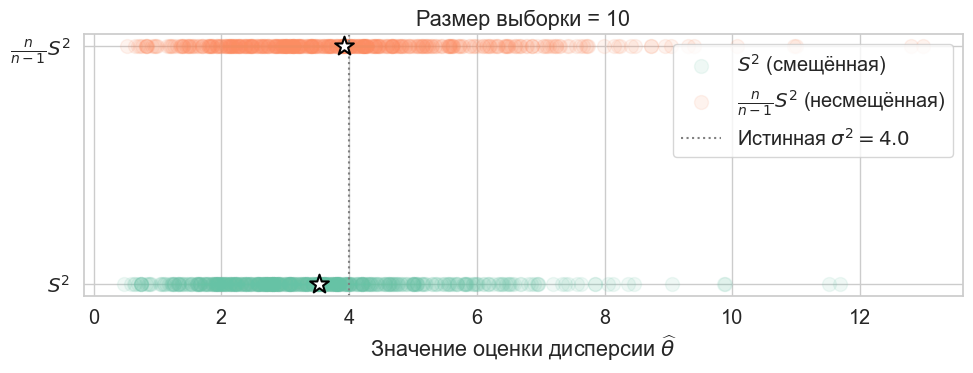

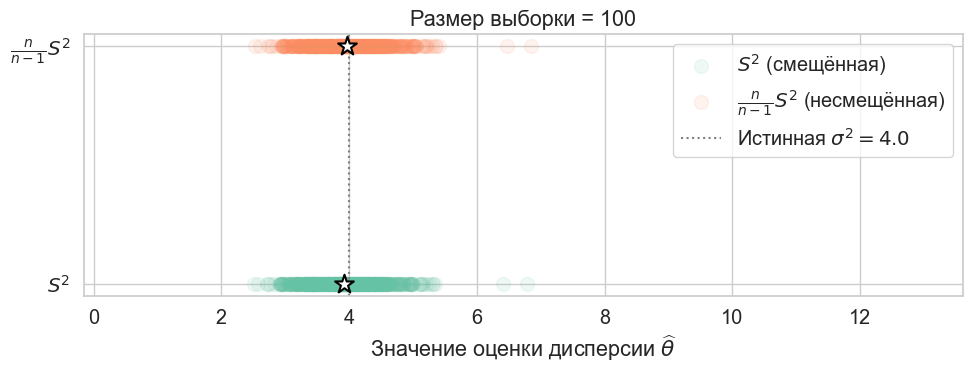

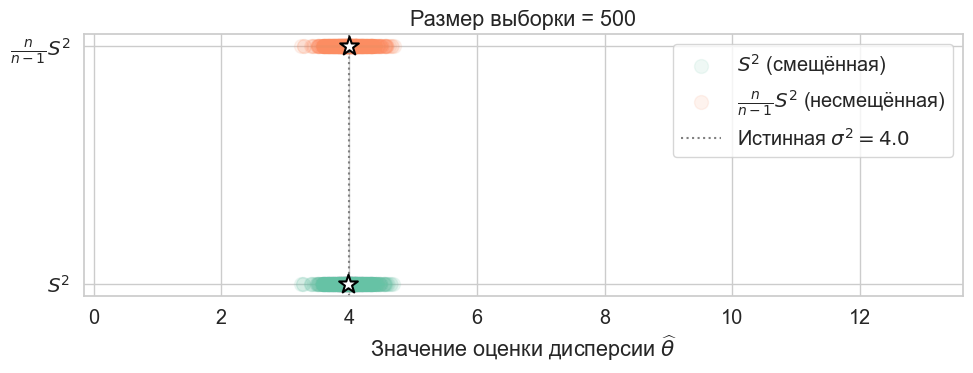

In [24]:
np.random.seed(45)
sns.set(palette="Set2", style="whitegrid", font_scale=1.3)

sigma_true = 2.0
true_var = sigma_true ** 2
sample_count = 500
sample_sizes = [10, 100, 500]
all_results = {}

for sample_size in sample_sizes:
    samples = np.random.normal(loc=0, scale=sigma_true, size=(sample_count, sample_size))

    est_biased = samples.var(axis=1, ddof=0)  # S^2, делим на n
    est_unbiased = samples.var(axis=1, ddof=1)  # n/(n-1)*S^2, делим на n-1
    all_results[sample_size] = (est_biased, est_unbiased)

# Вычисление общего масштаба X для всех графиков
all_values = np.concatenate([
    np.concatenate(values) for values in all_results.values()
])

x_min = all_values.min()
x_max = all_values.max()
x_margin = 0.05 * (x_max - x_min)

for sample_size, (est_biased, est_unbiased) in all_results.items():
    estimations = [est_biased, est_unbiased]
    colors = sns.color_palette("Set2")
    labels = [r"$S^2$ (смещённая)", r"$\frac{n}{n-1}S^2$ (несмещённая)"]

    # Вначале:
    plt.figure(figsize=(10, 4))

    # Для каждой оценки:
    # estimation_index - номер оценки
    for estimation_index, (est, color, label) in enumerate(zip(estimations, colors, labels)):
        plt.scatter(
            est,  # независимые оценки
            np.zeros(sample_count) + estimation_index,
            alpha=0.1,
            s=100,
            color=color,
            label=label,
        )
        plt.scatter(
            est.mean(),  # среднее независимых оценок
            estimation_index,
            marker="*",
            s=200,
            color="w",
            edgecolors="black",
            linewidths=1.5,
            zorder=5,
        )

    # Для всего графика:
    plt.axvline(true_var, ls=":", color="grey", label=f"Истинная $\\sigma^2={sigma_true**2}$")
    plt.xlim(x_min - x_margin, x_max + x_margin)
    plt.title(f"Размер выборки = {sample_size}")
    plt.xlabel(r"Значение оценки дисперсии $\widehat{\theta}$")
    plt.yticks([0, 1], [r"$S^2$", r"$\frac{n}{n-1}S^2$"])
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

**Решение:**

In [ ]:
# смотрть решение выше

**2.** Изучим поведение среднего оценок из первого пункта при росте размера выборки. Постройте график зависимости $\widetilde{\theta}$ от $n$ для двух типов оценок. Для вычисления зависимости нужно один раз сгенерировать выборки из пункта 1 достаточно большого размера (не более 500) и посчитать оценки по подвыборкам, используя <a href="https://thetahat.ru/courses/python/03"  target="_top">функции</a> из `numpy`. Использовать циклы, а так же функции, разворачивающиеся в цикл (например, `np.vectorize`), запрещено.

**Решение:**

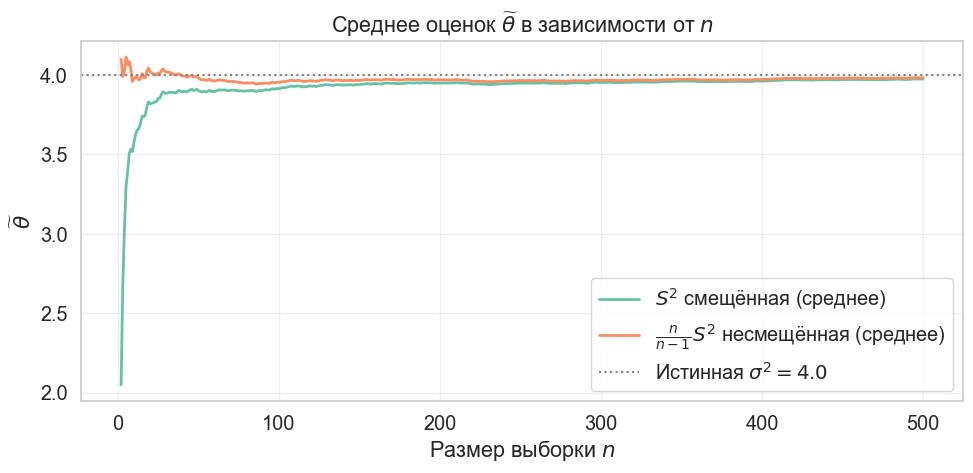

In [30]:
np.random.seed(45)
n_max = 500
k = 500
sigma_true = 2.0
true_var = sigma_true ** 2

big_samples = np.random.normal(loc=0, scale=sigma_true, size=(k, n_max))

cumsum = np.cumsum(big_samples, axis=1)
cumsum2 = np.cumsum(big_samples**2, axis=1)
counts = np.arange(1, n_max + 1)

sample_mean = cumsum / counts
sample_mean_of_squares = cumsum2 / counts
biased_var_all = sample_mean_of_squares - sample_mean**2

# берём только n >= 2
ns_plot = np.arange(2, n_max + 1)
biased_var = biased_var_all[:, 1:]

correction = ns_plot / (ns_plot - 1)
unbiased_var = biased_var * correction

theta_biased = biased_var.mean(axis=0)
theta_unbiased = unbiased_var.mean(axis=0)

plt.figure(figsize=(10, 5))
plt.plot(ns_plot, theta_biased, label=r"$S^2$ смещённая (среднее)", lw=2)
plt.plot(ns_plot, theta_unbiased, label=r"$\frac{n}{n-1}S^2$ несмещённая (среднее)", lw=2)
plt.axhline(sigma_true**2, ls=":", color="grey", label=f"Истинная $\\sigma^2 = {sigma_true**2}$")
plt.xlabel("Размер выборки $n$")
plt.ylabel(r"$\widetilde{\theta}$")
plt.title(r"Среднее оценок $\widetilde{\theta}$ в зависимости от $n$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task2_2.png", dpi=120)
plt.show()

**3.** Сделайте вывод о том, что такое свойство несмещенности. Подтверждают ли сделанные эксперименты полученное в теоретических задачах свойство несмещенности (или отсутствие этого свойства) данных оценок?

*Если у вас есть физика.* Поясните, почему в лабораторных по физике при оценке погрешности иногда используют $n-1$ в знаменателе, а не $n$. На самом деле для ответа на вопрос достаточно понимания текущего материала, ничего из физики знать не требуется.

**Вывод:**

**Несмещённость** — это свойство оценки, при котором её математическое ожидание совпадает с истинным параметром: $\mathbb{E}[\hat{\theta}] = \theta$. Если в среднем оценка промахивается — она смещённая.

Эксперименты полностью подтверждают теорию:

* $S^2$ (делим на $n$): звёздочки (средние по 500 оценкам) всегда стоят левее истинного $\sigma^2$ — систематическое занижение, что соответствует $\frac{n-1}{n}\sigma^2 < \sigma^2$.
* $\frac{n}{n-1}S^2$ (делим на $n-1$): звёздочки попадают прямо на истинное значение при любом $n$.
* На графике зависимости от $n$ смещённая оценка сходится к $\sigma^2$ снизу и только при $n \to \infty$ догоняет несмещённую — смещение $\frac{\sigma^2}{n}$ убывает, но не исчезает.

В лабораторных работах по физике часто используют знаменатель $n-1$, а не $n$, потому что мы не знаем истинное среднее и заменяем его выборочным средним, рассчитанным по тем же данным. Из-за этого теряется одна степень свободы: сумма всех отклонений всегда равна нулю, и достаточно знать лишь n−1 из них. Поэтому для получения несмещённой оценки дисперсии сумму квадратов отклонений делят не на n, а на n−1.

*Замечание.* Проведенные эксперименты позволяют сделать вывод только о поведении среднего значения оценки, но ничего не говорят о том, насколько велик их разброс относительно среднего.

 ---
### Задача 3.   


Вернемся к задачам 1 из заданий 5 и 6, где вы строили полносвязные и сверточные нейронные сети для классификации MNIST. Возьмите две модели:
1. модель, имеющая наилучшее качество по метрике accuracy;
2. любая другая модель *с меньшим количеством параметров*, которая не сильно хуже по качеству, чем первая модель.

Действительно ли вы уверены в том, что первая модель действительно точнее предсказывает? Или, может быть, это отличие в пределах погрешностей? Если так, то, может быть, взять более легкую модель? Давайте проверим это.

**1.** Загрузите данные. Определите две выбранные модели и обучите их.

In [31]:
# Загрузка данных (из ДЗ 6)
train_dataset = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transforms.ToTensor()
)
val_dataset = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transforms.ToTensor()
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

In [32]:
# Модель A — лучшая
model_A = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(128 * 3 * 3, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 10)
)

# Модель B — лёгкая
model_B = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 14 * 14, 10)
)

In [33]:
def accuracy_from_logits(logits, labels):
    preds = logits.argmax(dim=1)
    return (preds == labels).float().mean().item()

def evaluate_model(model, batch_gen, criterion, device="cpu"):
    """Оценивает модель: возвращает средний loss и accuracy."""
    model.eval()
    total_loss = 0.0
    total_acc = 0.0
    total_size = 0
    
    with torch.no_grad():
        for images, labels in batch_gen:
            images = images.to(device)
            labels = labels.to(device)
            
            logits = model(images)
            loss = criterion(logits, labels)
            acc = accuracy_from_logits(logits, labels)
            
            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            total_acc += acc * batch_size
            total_size += batch_size
    
    return total_loss / total_size, total_acc / total_size

def train_model(model, train_loader, val_loader, num_epochs=40, device="cpu"):
    """Обучает модель, возвращает модель, историю метрик и время обучения."""
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
    
    history = defaultdict(list)
    start_time = time.time()
    
    for epoch in range(1, num_epochs + 1):
        # Обучение
        model.train()
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
        
        # Валидация
        train_loss, train_acc = evaluate_model(model, train_loader, criterion, device)
        val_loss, val_acc = evaluate_model(model, val_loader, criterion, device)
        
        # Сохраняем историю
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        
        print(f"Epoch {epoch}: train_loss={train_loss:.4f}, train_acc={train_acc:.4f}, "
              f"val_loss={val_loss:.4f}, val_acc={val_acc:.4f}")
    
    elapsed_time = time.time() - start_time
    return model, history, elapsed_time

In [34]:
model_A, history_A, _ = train_model(model_A, train_loader, val_loader, num_epochs=20)
model_B, history_B, _ = train_model(model_B, train_loader, val_loader, num_epochs=20)

print(f"Model A val_acc: {max(history_A['val_acc']):.4f}")
print(f"Model B val_acc: {max(history_B['val_acc']):.4f}")

Epoch 1: train_loss=0.8295, train_acc=0.7636, val_loss=0.8078, val_acc=0.7745
Epoch 2: train_loss=0.2628, train_acc=0.9179, val_loss=0.2472, val_acc=0.9212
Epoch 3: train_loss=0.1721, train_acc=0.9458, val_loss=0.1618, val_acc=0.9481
Epoch 4: train_loss=0.1297, train_acc=0.9596, val_loss=0.1206, val_acc=0.9598
Epoch 5: train_loss=0.1187, train_acc=0.9631, val_loss=0.1073, val_acc=0.9663
Epoch 6: train_loss=0.0813, train_acc=0.9752, val_loss=0.0763, val_acc=0.9763
Epoch 7: train_loss=0.0755, train_acc=0.9766, val_loss=0.0728, val_acc=0.9780
Epoch 8: train_loss=0.0636, train_acc=0.9802, val_loss=0.0608, val_acc=0.9796
Epoch 9: train_loss=0.0631, train_acc=0.9807, val_loss=0.0625, val_acc=0.9792
Epoch 10: train_loss=0.0555, train_acc=0.9825, val_loss=0.0557, val_acc=0.9822
Epoch 11: train_loss=0.0479, train_acc=0.9851, val_loss=0.0475, val_acc=0.9830
Epoch 12: train_loss=0.0455, train_acc=0.9859, val_loss=0.0473, val_acc=0.9848
Epoch 13: train_loss=0.0429, train_acc=0.9868, val_loss=0.044

**Ответ на вопрос:**

На первый взгляд кажется, что Model A (98.92%) явно лучше Model B (97.30%) — разница 1.62%. Но эксперименты показали, что на подвыборке из 500 объектов доверительный интервал $(-0.0058,\ 0.0138)$ пересекает ноль, то есть на такой небольшой выборке статистически мы **не можем** утверждать превосходство модели A. Для стратифицированной подвыборки размера 500 доверительный интервал также пересекает ноль: $(-0.0086,\ 0.0126)$. Поэтому и в этом случае статистически значимое превосходство одной модели над другой не подтверждается. Только на всей тестовой выборке из 10 000 объектов интервал $(0.0131,\ 0.0193)$ полностью уходит в положительную область — и лишь тогда можно с уверенностью 95% сказать, что Model A действительно лучше. Так что брать более лёгкую модель B в данном случае **не стоит** — разница реальная, просто для её обнаружения нужна достаточно большая тестовая выборка.

**2.** В реальности мы обычно используем всю имеющуюся тестовую выборку. Но давайте для начала в рамках учебной задачи выберем случайную подвыборку (не стратифицированно) тестовой выборки размера 500 изображений. По этой выборке постройте интервал для разности метрик accuracy исследуемых моделей. 

<details>
<summary> ➡️ Подсказка </summary>
    По аналогии с примером с занятия определи <code>errors_A</code> и <code>errors_B</code> по следующему правилу. Если модель угадала правильный ответ, ставь 1, если ошиблась &mdash; ставь 0.
</details>

In [35]:
def calculate_stats(sample: np.ndarray):
    """
    Расчет точечной оценки среднего и границ доверительного интервала.

    :param sample: Массив данных (выборка) для статистического анализа.
    :return: Среднее значение, левая граница и правая граница интервала.
    """
    size = len(sample)
    std  = np.std(sample, ddof=1) / np.sqrt(size)
    mean = np.mean(sample)
    left  = mean - 2 * std
    right = mean + 2 * std
    return mean, left, right


def show_interval(mean: float, left: float, right: float) -> None:
    """
    Визуализация доверительного интервала и точечной оценки на графике.

    :param mean: Математическое ожидание или среднее значение для отображения точки.
    :param left: Значение левой границы интервала.
    :param right: Значение правой границы интервала.
    :return: Визуальный график matplotlib.
    """
    plt.figure(figsize=(10, 1))
    plt.axvline(0, 0, 1, color="gray", lw=2, alpha=0.6)
    plt.fill_between(
        [left, right],
        [0.15] * 2,
        [-0.15] * 2,
        color="#20b2aa",
        alpha=0.6,
    )
    
    plt.scatter(mean, 0, s=300, marker="*", color="red")
    plt.title(f"Delta Accuracy = {mean:.4f}, интервал ({left:.4f}, {right:.4f})")
    plt.ylim((-0.5, 0.5))
    plt.yticks([])
    plt.tight_layout()
    plt.show()

In [36]:
# Получаем предсказания и метки на всём тесте
model_A.eval()
model_B.eval()

all_preds_A, all_preds_B, all_labels = [], [], []

with torch.no_grad():
    for images, labels in val_loader:
        all_preds_A.append(model_A(images).argmax(dim=1).numpy())
        all_preds_B.append(model_B(images).argmax(dim=1).numpy())
        all_labels.append(labels.numpy())

all_preds_A = np.concatenate(all_preds_A)
all_preds_B = np.concatenate(all_preds_B)
all_labels = np.concatenate(all_labels)

# 1 если угадала, 0 если ошиблась
correct_A = (all_preds_A == all_labels).astype(float)
correct_B = (all_preds_B == all_labels).astype(float)
diff_all = correct_A - correct_B

/var/folders/c4/ygnydvfn6nv_3xpjt4k99_xr0000gn/T/ipykernel_12463/1687728069.py:39: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


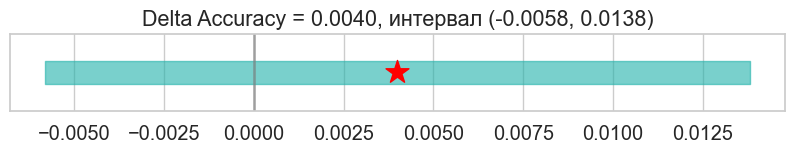

In [38]:
np.random.seed(42)
idx_random  = np.random.choice(len(all_labels), size=500, replace=False)
diff_random = diff_all[idx_random]

mean, left, right = calculate_stats(diff_random)
show_interval(mean, left, right)

Теперь выберите тестовую подвыборку стратифицированно. Удалось ли уменьшить длину интервала?

/var/folders/c4/ygnydvfn6nv_3xpjt4k99_xr0000gn/T/ipykernel_12463/1687728069.py:39: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


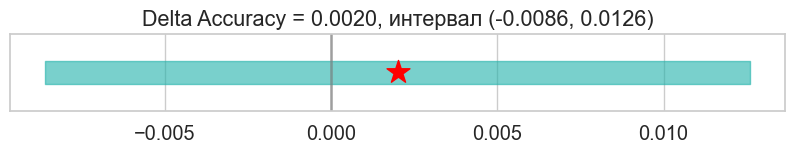

In [40]:
sss = StratifiedShuffleSplit(n_splits=1, test_size=500, random_state=42)
idx_strat = next(sss.split(all_labels, all_labels))[1]
diff_strat = diff_all[idx_strat]

mean, left, right = calculate_stats(diff_strat)
show_interval(mean, left, right)

Наконец, постройте интервал по всей тестовой выборке.

/var/folders/c4/ygnydvfn6nv_3xpjt4k99_xr0000gn/T/ipykernel_12463/1687728069.py:39: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


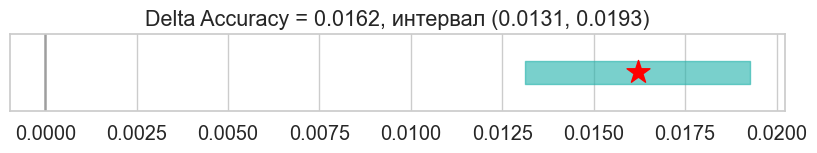

In [42]:
mean, left, right = calculate_stats(diff_all)
show_interval(mean, left, right)

In [43]:
mean_random, left_random, right_random = calculate_stats(diff_random)
mean_strat, left_strat, right_strat = calculate_stats(diff_strat)
mean_all, left_all, right_all = calculate_stats(diff_all)

length_random = right_random - left_random
length_strat = right_strat - left_strat
length_all = right_all - left_all

print("Нестратифицированная подвыборка:")
print(f"Интервал: ({left_random:.4f}, {right_random:.4f})")
print(f"Длина интервала: {length_random:.4f}")

print("\nСтратифицированная подвыборка:")
print(f"Интервал: ({left_strat:.4f}, {right_strat:.4f})")
print(f"Длина интервала: {length_strat:.4f}")

print("\nВся тестовая выборка:")
print(f"Интервал: ({left_all:.4f}, {right_all:.4f})")
print(f"Длина интервала: {length_all:.4f}")

Нестратифицированная подвыборка:
Интервал: (-0.0058, 0.0138)
Длина интервала: 0.0196

Стратифицированная подвыборка:
Интервал: (-0.0086, 0.0126)
Длина интервала: 0.0212

Вся тестовая выборка:
Интервал: (0.0131, 0.0193)
Длина интервала: 0.0061


**3.** Сделайте выводы о сравнении моделей.

**Случайная подвыборка 500:** интервал $(-0.0058,\ 0.0138)$ **пересекает ноль** — статистически мы не можем утверждать, что модель A лучше модели B.

**Стратифицированная подвыборка 500:** интервал $(-0.0086,\ 0.0126)$ — тоже пересекает ноль.

При этом стратификация не уменьшила длину доверительного интервала:
- случайная подвыборка: длина интервала = 0.0196;
- стратифицированная подвыборка: длина интервала = 0.0212.
В данном эксперименте стратификация не дала выигрыша, поскольку датасет MNIST уже является достаточно хорошо сбалансированным по классам, а сами модели показывают очень высокую accuracy.

**Вся тестовая выборка (10 000):** интервал $(0.0131,\ 0.0193)$ — **не пересекает ноль**. Только на полной выборке мы можем статистически значимо утверждать, что модель A (kernel_3x3, 98.92%) действительно лучше модели B (model_1, 97.30%).

Пусть вы сделали вывод о том, что одна модель действительно лучше другой по качеству. Какова ваша уверенность в ответе?

<details>
<summary> ➡️ Подсказка </summary>
    Уверенность в статистическом смысле, а не в том, правильно ли вы решили задачу 😀
</details>


**Уверенность в ответе.** По правилу двух сигм для нормального приближения я строю 95%-й доверительный интервал. Поэтому, если интервал не пересекает ноль, я делаю вывод о статистически значимом отличии моделей с уверенностью около **95%**. Это значит, что если бы мы повторили эксперимент много раз, в 95% случаев интервал накрывал бы истинную разность accuracy.

Предположим, что вы сравниваете три модели, и в результате получили, что:
* модель 1 лучше модели 2,
* модель 2 лучше модели 3.

Какова ваша уверенность в таком ответе?

<details>
<summary> ➡️ Подсказка </summary>
    Возможно, вы не сможете точно ответить на этот вопрос, и это нормально. Достаточно привести лишь общие рассуждения в сторону правильного ответа. 
    
На самом деле, на практике многие отвечают на подобные вопросы неправильно &mdash; как студенты на экзамене, так и потенциальные стажеры на собеседованиях, и даже джуны/миддлы. Для того, чтобы уверенно отвечать на такие вопросы, у вас есть курс статистики на 3 курсе! Ждем вас ❤️
</details>

**Три модели.** Если я сравниваю три модели и делаю два вывода: модель 1 лучше модели 2, а модель 2 лучше модели 3, каждое на уровне уверенности 95%, то уверенность в обоих выводах одновременно уже меньше 95%. Если считать сравнения независимыми, то она равна $0.95 \times 0.95 = 0.9025$, то есть уверенность падает примерно до **90%**. В общем случае точную уверенность сказать нельзя, потому что сравнения могут быть зависимыми. Это пример проблемы множественных сравнений: чем больше проверок, тем выше вероятность ошибиться хотя бы в одном выводе. Для её решения используют специальные поправки, например поправку Бонферрони.

---
© 2026 команда <a href="https://thetahat.ru/">ThetaHat</a> для ВвАД